In [2]:
import pandas as pd

# Electricity Consumption Dataset

In [3]:
df_kwh = pd.read_csv(r"C:\Users\Asus\OneDrive\Desktop\Sem 10 September 2026\Final Year Project 2\dataset\kwh_per_household.csv")

# 1. Rename columns
df_kwh = df_kwh.rename(
    columns={
        "domestic_mkwh": "domestic_consumption_m_kwh",
        "households": "total_households",
        "kwh_per_household": "avg_kwh_per_household",
    }
)

# 2. Filter rows (2018-01 to 2026-06)
df_kwh["date"] = pd.to_datetime(df_kwh["date"])
df_kwh = df_kwh[
    (df_kwh["date"] >= "2018-01-01") & (df_kwh["date"] <= "2026-06-30")
]

# 3. Select columns
df_kwh = df_kwh[
    [
        "date",
        "domestic_consumption_m_kwh",
        "total_households",
        "avg_kwh_per_household",
    ]
]

# 4. Data type conversion
df_kwh["date"] = df_kwh["date"].dt.tz_localize(None)
df_kwh["domestic_consumption_m_kwh"] = df_kwh[
    "domestic_consumption_m_kwh"
].astype(float)
df_kwh["total_households"] = df_kwh["total_households"].astype(int)
df_kwh["avg_kwh_per_household"] = df_kwh["avg_kwh_per_household"].astype(float)

# 5. Feature Engineering (Temporal & Absolute kWh)
df_kwh["year"] = df_kwh["date"].dt.year
df_kwh["month"] = df_kwh["date"].dt.month
df_kwh["quarter"] = df_kwh["date"].dt.quarter
df_kwh["total_consumption_kwh"] = df_kwh["domestic_consumption_m_kwh"] * 1e6

# Environmental Condition Dataset

In [4]:
df_weather = pd.read_csv(r"C:\Users\Asus\OneDrive\Desktop\Sem 10 September 2026\Final Year Project 2\dataset\weather_monthly_average.csv")

# 1. Rename columns
df_weather = df_weather.rename(
    columns={
        "temperature_C": "mean_temperature_c",
        "humidity_pct": "mean_humidity_pct",
        "rainfall_mm_per_day": "mean_rainfall_mm_per_day",
        "wind_speed_m_s": "mean_wind_speed_ms",
    }
)

# 2. Filter rows
df_weather["date"] = pd.to_datetime(df_weather["date"])
df_weather = df_weather[
    (df_weather["date"] >= "2018-01-01") & (df_weather["date"] <= "2026-06-30")
]

# 3. Select columns
df_weather = df_weather[
    [
        "date",
        "mean_temperature_c",
        "mean_humidity_pct",
        "mean_rainfall_mm_per_day",
        "mean_wind_speed_ms",
    ]
]

# 4. Data type conversion
df_weather["date"] = df_weather["date"].dt.tz_localize(None)
for col in [
    "mean_temperature_c",
    "mean_humidity_pct",
    "mean_rainfall_mm_per_day",
    "mean_wind_speed_ms",
]:
    df_weather[col] = df_weather[col].astype(float)

# 5. Feature Engineering (Fahrenheit conversion)
df_weather["temp_fahrenheit"] = df_weather["mean_temperature_c"] * 9 / 5 + 32

# Merge Datasets

In [16]:
df_final = pd.merge(df_kwh, df_weather, on="date", how="inner")

# Export final clean dataset for thesis analysis
df_final.to_csv("clean_merged_dataset.csv", index=False)

print("Dataset merging complete!")
print("Final Dataset Shape:", df_final.shape)
print(df_final.head(3))

Dataset merging complete!
Final Dataset Shape: (102, 13)
        date  domestic_consumption_m_kwh  total_households  \
0 2018-01-01                 2455.819450           8452376   
1 2018-02-01                 2530.541863           8470523   
2 2018-03-01                 2584.769732           8488380   

   avg_kwh_per_household  year  month  quarter  total_consumption_kwh  \
0             290.547823  2018      1        1           2.455819e+09   
1             298.746826  2018      2        1           2.530542e+09   
2             304.506835  2018      3        1           2.584770e+09   

   mean_temperature_c  mean_humidity_pct  mean_rainfall_mm_per_day  \
0           25.558125          87.002500                  11.33125   
1           25.692500          82.988125                   3.52250   
2           26.671250          82.744375                   4.50750   

   mean_wind_speed_ms  temp_fahrenheit  
0            1.592500        78.004625  
1            2.034375        78.246500

# Data Summarization

In [17]:
# 1. Load your cleaned dataset
df = pd.read_csv(r"C:\Users\Asus\OneDrive\Desktop\Sem 10 September 2026\Final Year Project 2\dataset\clean_merged_dataset.csv")

# 2. Select key variables for your thesis summary table
thesis_vars = [
    "domestic_consumption_m_kwh",
    "total_households",
    "avg_kwh_per_household",
    "mean_temperature_c",
    "mean_humidity_pct",
    "mean_rainfall_mm_per_day",
    "mean_wind_speed_ms",
]

# 3. Generate summary statistics (Count, Mean, Std, Min, Median, Max)
summary_table = df[thesis_vars].describe().T[["count", "mean", "std", "min", "50%", "max"]]

# Rename columns for professional thesis presentation
summary_table.columns = [
    "Sample Size (N)",
    "Mean",
    "Std. Deviation",
    "Minimum",
    "Median",
    "Maximum",
]

# Round to 2 decimal places for neatness
summary_table = summary_table.round(2)

# Display table in console
print("=== Descriptive Statistics Summary Table ===")
print(summary_table.to_string())

# Optional: Export directly to CSV for your thesis report
summary_table.to_csv("thesis_descriptive_statistics.csv")

=== Descriptive Statistics Summary Table ===
                            Sample Size (N)        Mean  Std. Deviation     Minimum      Median      Maximum
domestic_consumption_m_kwh            102.0     3238.12          430.20     2455.82     3223.21      4233.08
total_households                      102.0  9360043.78       539258.93  8452376.00  9358439.00  10120897.00
avg_kwh_per_household                 102.0      344.74           29.67      290.55      341.48       442.16
mean_temperature_c                    102.0       26.81            0.67       25.34       26.84        28.51
mean_humidity_pct                     102.0       83.82            1.67       79.55       83.74        87.89
mean_rainfall_mm_per_day              102.0        8.47            3.49        2.61        8.34        19.00
mean_wind_speed_ms                    102.0        1.63            0.24        1.24        1.58         2.24


In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

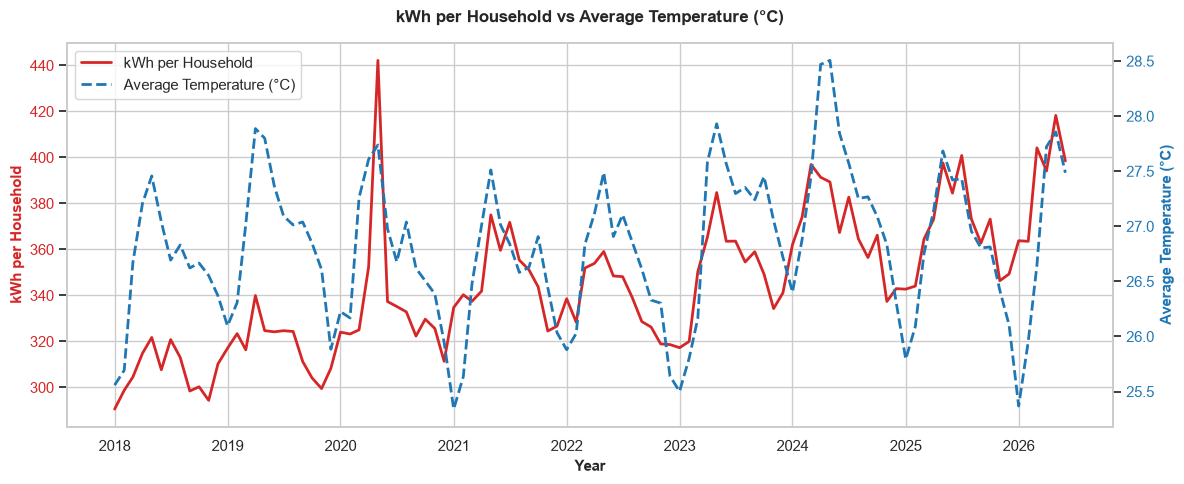

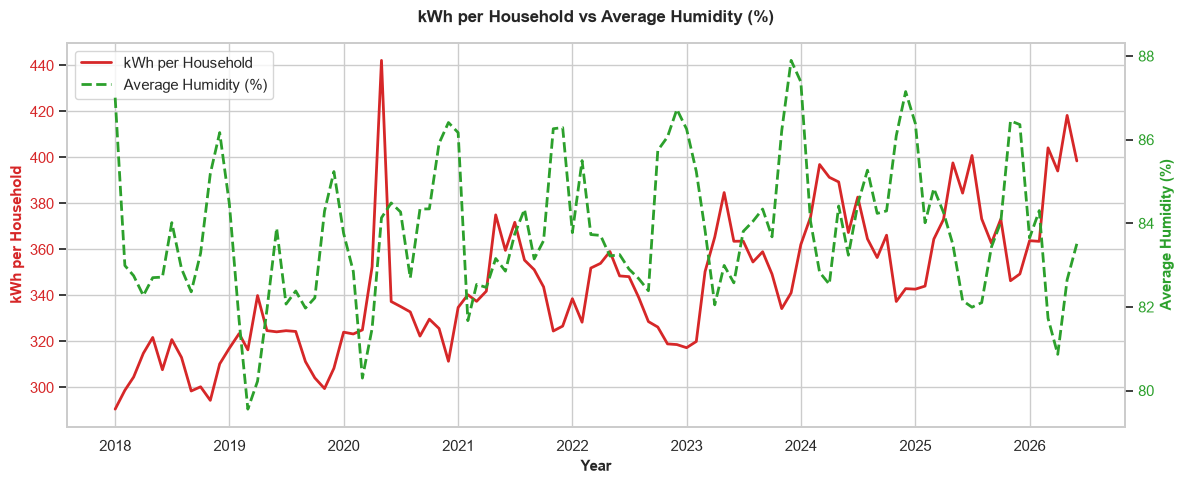

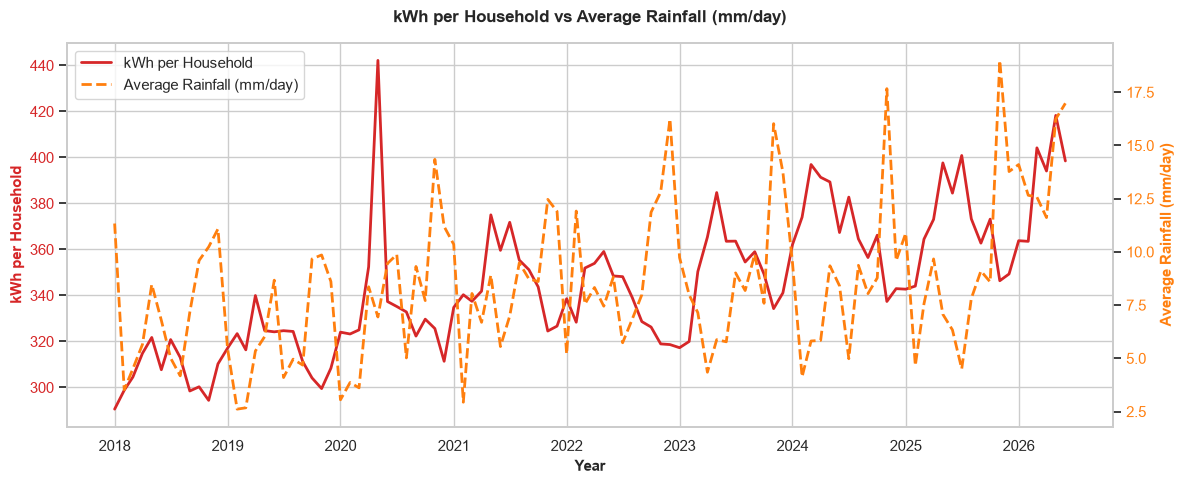

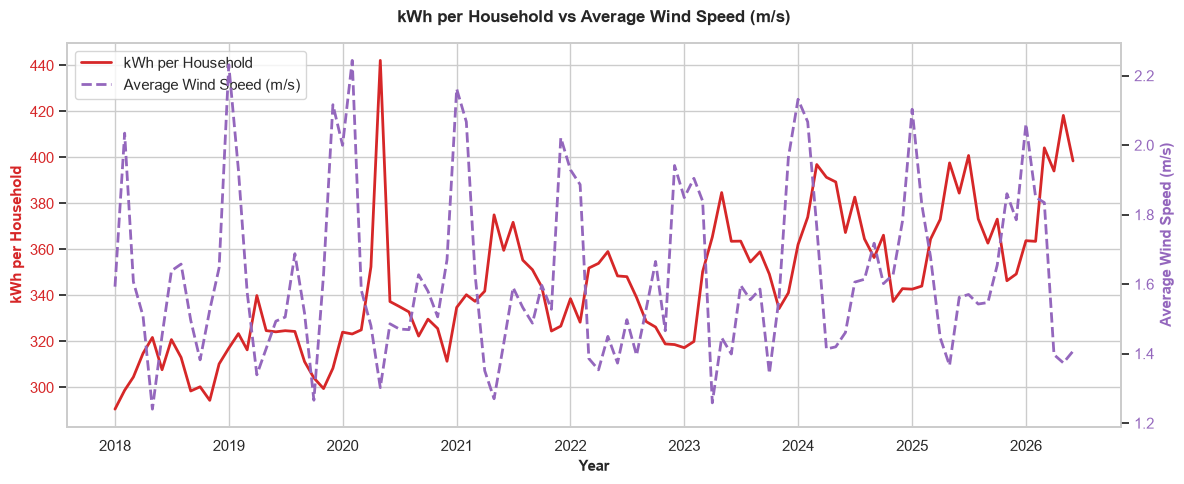

In [19]:
# 1. Load your cleaned dataset
df = pd.read_csv(r"C:\Users\Asus\OneDrive\Desktop\Sem 10 September 2026\Final Year Project 2\dataset\clean_merged_dataset.csv")
df["date"] = pd.to_datetime(df["date"])

# Ensure consistent column naming
rename_dict = {
    "mean_temperature_c": "avg_temperature_c",
    "mean_humidity_pct": "avg_humidity_pct",
    "mean_rainfall_mm_per_day": "avg_rainfall_mm_per_day",
    "mean_wind_speed_ms": "avg_wind_speed_ms",
}
df = df.rename(columns={k: v for k, v in rename_dict.items() if k in df.columns})

sns.set_theme(style="whitegrid")

# 2. Function to create dual-axis relationship plots
def plot_dual_axis(df, weather_col, weather_label, color, filename):
    fig, ax1 = plt.subplots(figsize=(12, 5))

    # Left Axis: Electricity Consumption
    color_elec = "#d62728"
    ax1.set_xlabel("Year", fontsize=11, fontweight="bold")
    ax1.set_ylabel("kWh per Household", color=color_elec, fontsize=11, fontweight="bold")
    line1 = ax1.plot(df["date"], df["avg_kwh_per_household"], color=color_elec, linewidth=2, label="kWh per Household")
    ax1.tick_params(axis="y", labelcolor=color_elec)

    # Right Axis: Weather Variable
    ax2 = ax1.twinx()  
    ax2.set_ylabel(weather_label, color=color, fontsize=11, fontweight="bold")
    line2 = ax2.plot(df["date"], df[weather_col], color=color, linewidth=2, linestyle="--", label=weather_label)
    ax2.tick_params(axis="y", labelcolor=color)
    ax2.grid(False) # Prevent overlapping gridlines

    # Title & Layout
    plt.title(f"kWh per Household vs {weather_label}", fontsize=12, fontweight="bold", pad=15)
    
    # Combine legends
    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc="upper left")

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

# 3. Generate individual relationship plots for thesis inclusion
plot_dual_axis(df, "avg_temperature_c", "Average Temperature (°C)", "#1f77b4", "relationship_kwh_vs_temperature.png")
plot_dual_axis(df, "avg_humidity_pct", "Average Humidity (%)", "#2ca02c", "relationship_kwh_vs_humidity.png")
plot_dual_axis(df, "avg_rainfall_mm_per_day", "Average Rainfall (mm/day)", "#ff7f0e", "relationship_kwh_vs_rainfall.png")
plot_dual_axis(df, "avg_wind_speed_ms", "Average Wind Speed (m/s)", "#9467bd", "relationship_kwh_vs_wind.png")

# Feature & Lag Selection

In [ ]:
# Ensure date is sorted chronologically
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

# 2. Automatically rename columns if they still use 'mean_' prefix
rename_map = {
    "mean_temperature_c": "avg_temperature_c",
    "mean_humidity_pct": "avg_humidity_pct",
    "mean_rainfall_mm_per_day": "avg_rainfall_mm_per_day",
    "mean_wind_speed_ms": "avg_wind_speed_ms",
}
df = df.rename(columns={k: v for k, v in rename_map.items() if k in df.columns})

# 3. Define Target Variable
target = "avg_kwh_per_household"

# 4. Create Lag Features for historical context
df["kwh_lag_1"] = df["avg_kwh_per_household"].shift(1)
df["kwh_lag_2"] = df["avg_kwh_per_household"].shift(2)

df["temp_lag_1"] = df["avg_temperature_c"].shift(1)
df["humidity_lag_1"] = df["avg_humidity_pct"].shift(1)
df["rainfall_lag_1"] = df["avg_rainfall_mm_per_day"].shift(1)
df["wind_lag_1"] = df["avg_wind_speed_ms"].shift(1)

# 5. Define All Input Features (Base + Lags)
features = [
    "total_households",
    "avg_temperature_c",
    "avg_humidity_pct",
    "avg_rainfall_mm_per_day",
    "avg_wind_speed_ms",
    "year",
    "month",
    "quarter",
    "kwh_lag_1",
    "kwh_lag_2",
    "temp_lag_1",
    "humidity_lag_1",
    "rainfall_lag_1",
    "wind_lag_1",
]

# 6. Drop missing rows created by shifting
df_modeled = df.dropna(subset=features + [target]).reset_index(drop=True)

print(f"Original dataset shape: {df.shape}")
print(f"Dataset shape after creating lags and dropping NaNs: {df_modeled.shape}")

# 7. Save model-ready dataset
df_modeled.to_csv("model_ready_dataset.csv", index=False)
print("Model-ready dataset saved successfully as 'model_ready_dataset.csv'!")

Original dataset shape: (102, 19)
Dataset shape after creating lags and dropping NaNs: (100, 19)
Model-ready dataset saved successfully as 'model_ready_dataset.csv'!


: 